# Makemore Part 5: Wavenet Model

> **Goal:** To build a wavenet and then compare it with the MLP Baseline

In [39]:
from pathlib import Path
import matplotlib.pyplot as plt 
import pandas as pd
import torch

In [40]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'
device

'cuda'

In [41]:
DATA_DIR = Path.cwd().parent / "data"
DATA_PATH = DATA_DIR / "names.txt"

words = DATA_PATH.read_text("utf-8").splitlines()
words[:10]

['emma',
 'olivia',
 'ava',
 'isabella',
 'sophia',
 'charlotte',
 'mia',
 'amelia',
 'harper',
 'evelyn']

In [42]:
chars = sorted(list(set(''.join(words))))
stoi = {s:i+1 for i,s in enumerate(chars)}
stoi['.'] = 0
itos = {i:s for s,i in stoi.items()}
vocab_size = len(itos)

In [81]:
# build the dataset
block_size = 6

def build_dataset(words):  
  X, Y = [], []
  
  for w in words:
    context = [0] * block_size
    for ch in w + '.':
      ix = stoi[ch]
      X.append(context)
      Y.append(ix)
      context = context[1:] + [ix]

  X = torch.tensor(X, device=device)
  Y = torch.tensor(Y, device=device)
  return X, Y

# Baseline MLP Model

In [82]:
from torch import nn
import torch.nn.functional as F


class MLP(nn.Module):
    def __init__(self, vocab_size, block_size, n_embd=10, n_hidden=300):
        super().__init__()
        self.C = nn.Parameter(torch.randn(vocab_size, n_embd) * 0.1)
        self.layers = nn.Sequential(
            nn.Linear(block_size * n_embd, n_hidden, bias=False),
            nn.BatchNorm1d(n_hidden),
            nn.Tanh(),

            nn.Linear(n_hidden, n_hidden, bias=False),
            nn.BatchNorm1d(n_hidden),
            nn.Tanh(),

            nn.Linear(n_hidden, vocab_size)
        )

        self.init_weights()


    def init_weights(self):
        with torch.no_grad():
            self.layers[-1].weight *= 0.1

    
    def forward(self, idx: torch.Tensor, targets=None): # idx: (32, 4)
        loss = None
        B, T = idx.shape
        X_emb = self.C[idx].reshape(B, -1) # (B, T, n_embd) --> (B, T * n_embd)
        logits = self.layers(X_emb)   # (B, block_size * n_embed)  @ (block_size * n_embd, n_hidden) --> (B, vocab_size)

        if targets is not None:
            loss = F.cross_entropy(logits, targets)

        return logits, loss

In [71]:
# Building the dataset
n1 = int(0.8*len(words))
n2 = int(0.9*len(words))

Xtr,  Ytr  = build_dataset(words[:n1])  
Xdev, Ydev = build_dataset(words[n1:n2])
Xte,  Yte  = build_dataset(words[n2:])

In [83]:
model = MLP(
    vocab_size=27, 
    block_size=block_size).to(device)

optimizer = torch.optim.SGD(model.parameters(), lr=0.1)

In [73]:
max_steps = 30000
batch_size = 128
lossi = []
val_lossi = []


for i in range(max_steps):
    ix = torch.randint(0, Xtr.shape[0], (batch_size,), device=device)
    Xb, yb = Xtr[ix], Ytr[ix]

    # Forward pass
    logits, loss = model(Xb, yb) 
    
    # Backward pass
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    # track loss
    lossi.append(loss.item())


    if i % 1000 == 0:
        with torch.no_grad():
            model.eval()
            val_loss = F.cross_entropy(model(Xdev)[0], Ydev)
        
        val_lossi.append(val_loss.item())
        
        print(f'{i:7d}/{max_steps}: Loss: {loss.item():.4f}  Val: {val_loss:.4f}')

      0/30000: Loss: 3.2978  Val: 3.2919
   1000/30000: Loss: 2.4999  Val: 2.5215
   2000/30000: Loss: 2.2110  Val: 2.4869
   3000/30000: Loss: 2.0374  Val: 2.4560
   4000/30000: Loss: 2.1776  Val: 2.4323
   5000/30000: Loss: 2.1270  Val: 2.4354
   6000/30000: Loss: 2.1321  Val: 2.4043
   7000/30000: Loss: 2.2993  Val: 2.4026
   8000/30000: Loss: 2.2303  Val: 2.3992
   9000/30000: Loss: 2.0978  Val: 2.3779
  10000/30000: Loss: 2.2661  Val: 2.3709
  11000/30000: Loss: 2.0213  Val: 2.3755
  12000/30000: Loss: 2.0426  Val: 2.3510
  13000/30000: Loss: 2.1414  Val: 2.3507
  14000/30000: Loss: 2.0139  Val: 2.3453
  15000/30000: Loss: 2.0748  Val: 2.3386
  16000/30000: Loss: 2.1110  Val: 2.3357
  17000/30000: Loss: 2.0942  Val: 2.3211
  18000/30000: Loss: 2.0382  Val: 2.3132
  19000/30000: Loss: 2.0251  Val: 2.3124
  20000/30000: Loss: 2.0288  Val: 2.3041
  21000/30000: Loss: 1.9361  Val: 2.3090
  22000/30000: Loss: 1.9923  Val: 2.2973
  23000/30000: Loss: 1.9495  Val: 2.3107
  24000/30000: L

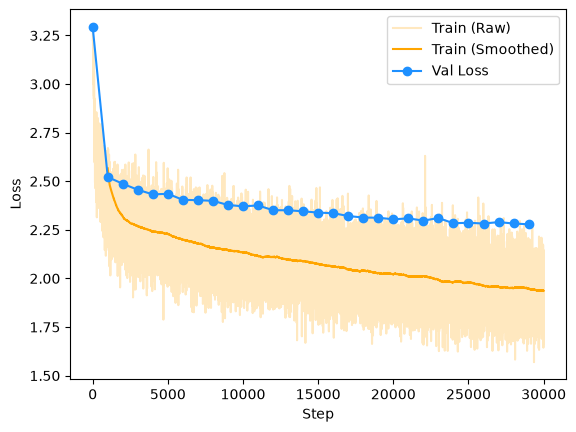

In [74]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. Raw train loss (faint)
plt.plot(lossi, color="orange", alpha=0.25, label="Train (Raw)")

# 2. Smoothed train loss
smooth = pd.Series(lossi).rolling(1000).mean()
plt.plot(smooth, color="orange", label="Train (Smoothed)")

# 3. Validation loss (80 points matched with val_steps)
val_steps = [i * 1000 for i in range(len(val_lossi))]
plt.plot(val_steps, val_lossi, color="dodgerblue", marker='o', label="Val Loss")

plt.xlabel("Step")
plt.ylabel("Loss")
plt.legend()
plt.show()

In [75]:
@torch.no_grad()
def split_loss(split):
    model.eval()
    x, y = {

        'val':   (Xdev, Ydev),
        'test':  (Xte, Yte),
    }[split]
    x, y = x.to(device), y.to(device)
    logits, loss = model(x, y)
    print(f'{split} loss: {loss.item():.4f}')

split_loss('val')
split_loss('test')


val loss: 2.2899
test loss: 2.3213


In [79]:
@torch.no_grad()
def generate(n=20):
    model.eval()
    for _ in range(n):
        out = []
        context = [0] * block_size

        while True:
            x = torch.tensor([context], device=device)  
            logits, loss = model(x)
            probs = F.softmax(logits, dim=1)
            ix = torch.multinomial(probs, num_samples=1).item()

            context = context[1:] + [ix]  
            out.append(ix)

            if ix == 0:     
                break

        print(''.join(itos[i] for i in out[:-1]))


generate(20)


rhiyba
ara
satara
jayde
evelynn
zianni
ataleya
anwesside
coral
jotum
kensley
rathavia
vianla
davayron
tydith
vaelyla
tezey
nivi
geyron
abray


# Wavenet

In [102]:
# build the dataset
block_size = 8

def build_dataset(words):  
  X, Y = [], []
  
  for w in words:
    context = [0] * block_size
    for ch in w + '.':
      ix = stoi[ch]
      X.append(context)
      Y.append(ix)
      context = context[1:] + [ix]

  X = torch.tensor(X, device=device)
  Y = torch.tensor(Y, device=device)
  return X, Y

In [103]:
# Building the dataset
n1 = int(0.8*len(words))
n2 = int(0.9*len(words))

Xtr,  Ytr  = build_dataset(words[:n1])  
Xdev, Ydev = build_dataset(words[n1:n2])
Xte,  Yte  = build_dataset(words[n2:])

In [112]:
n_embd = 10
n_hidden = 300


class Embedding(nn.Module):
    def __init__(self, vocab_size, n_embd):
        super().__init__()
        self.C = nn.Parameter(torch.randn(vocab_size, n_embd))


    def forward(self, x):
        return self.C[x]

class FlattenConsecutive(nn.Module):
    def __init__(self, n):
        super().__init__()
        self.n = n

    def forward(self, x):
        B, T, C = x.shape
        x = x.reshape(B, T// self.n, C * self.n)
        if x.shape[1] == 1:
            x = x.squeeze(1)
        return x

class BatchNorm1d(nn.Module):
    def __init__(self, num_features):
        super().__init__()
        self.bn = nn.BatchNorm1d(num_features)

    def forward(self, x):
        B, T, C = x.shape
        return self.bn(x.reshape(B * T, C)).reshape(B, T, C)


class Wavenet(nn.Module):
    def __init__(self, vocab_size, n_embd=10, n_hidden=300):
        super().__init__()

        self.layers = nn.Sequential(
            Embedding(vocab_size, n_embd),  # (B, 8, 10)
            FlattenConsecutive(2), # (B, 4, 20)

            nn.Linear(n_embd * 2, n_hidden, bias=False), # (B, 4, 20) @ (20, 300) --> (B, 4, 300)
            BatchNorm1d(n_hidden),
            nn.Tanh(),

            FlattenConsecutive(2), # (B, 2, 600)
            nn.Linear(n_hidden * 2, n_hidden,bias=False), # (B, 2, 600) @ (600, 300) --> (B, 2, 300)
            BatchNorm1d(n_hidden),
            nn.Tanh(),

            FlattenConsecutive(2), # (B, 1, 600) -> (B, 600)
            nn.Linear(n_hidden * 2, vocab_size)
        )

    def forward(self, x, target=None):
        logits = self.layers(x)
        loss = None
        if target is not None:
            loss = F.cross_entropy(logits, target)

        return logits, loss

        


    

In [118]:
wavenet_model = Wavenet(vocab_size=27, n_embd=10, n_hidden=300).to(device)
optimizer = torch.optim.SGD(wavenet_model.parameters(), lr=0.1)
sum(p.numel() for p in wavenet_model.parameters())

203697

In [119]:
max_steps = 80000
batch_size = 128
lossi = []
val_lossi = []


for i in range(max_steps):
    # minibatch
    ix = torch.randint(0, Xtr.shape[0], (batch_size,), device=device)
    Xb, Yb = Xtr[ix], Ytr[ix]

    # forward
    logits, loss = wavenet_model(Xb, Yb) 

    # backward
    optimizer.zero_grad()
    loss.backward()

    # update
    optimizer.step()

    # track loss
    lossi.append(loss.item())

    # stats
    if i % 1000 == 0 or i == max_steps - 1:
        
        with torch.no_grad():
            wavenet_model.eval()
            val_loss = F.cross_entropy(wavenet_model(Xdev)[0], Ydev)
        val_lossi.append(val_loss.item())
        print(f'{i:7d}/{max_steps:7d}: Loss: {loss.item():.4f}  Val: {val_loss.item():.4f}')  

      0/  80000: Loss: 3.3267  Val: 3.1763
   1000/  80000: Loss: 2.1592  Val: 2.4761
   2000/  80000: Loss: 2.2602  Val: 2.4317
   3000/  80000: Loss: 2.0392  Val: 2.3860
   4000/  80000: Loss: 2.1200  Val: 2.3710
   5000/  80000: Loss: 2.1692  Val: 2.3516
   6000/  80000: Loss: 1.9879  Val: 2.3429
   7000/  80000: Loss: 1.9015  Val: 2.3331
   8000/  80000: Loss: 1.9335  Val: 2.3016
   9000/  80000: Loss: 2.1056  Val: 2.3079
  10000/  80000: Loss: 1.8905  Val: 2.3039
  11000/  80000: Loss: 2.1874  Val: 2.2924
  12000/  80000: Loss: 2.1259  Val: 2.2735
  13000/  80000: Loss: 1.8333  Val: 2.2966
  14000/  80000: Loss: 1.9576  Val: 2.2800
  15000/  80000: Loss: 1.9536  Val: 2.2773
  16000/  80000: Loss: 2.1137  Val: 2.2875
  17000/  80000: Loss: 1.9307  Val: 2.2706
  18000/  80000: Loss: 1.9765  Val: 2.2959
  19000/  80000: Loss: 1.9429  Val: 2.2860
  20000/  80000: Loss: 1.8918  Val: 2.2847
  21000/  80000: Loss: 1.9555  Val: 2.2856
  22000/  80000: Loss: 1.8517  Val: 2.2855
  23000/  8

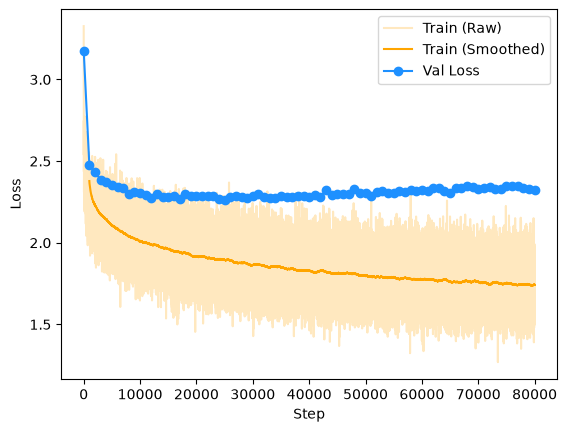

In [125]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. Raw train loss (faint)
plt.plot(lossi, color="orange", alpha=0.25, label="Train (Raw)")

# 2. Smoothed train loss
smooth = pd.Series(lossi).rolling(1000).mean()
plt.plot(smooth, color="orange", label="Train (Smoothed)")

# 3. Validation loss (80 points matched with val_steps)
val_steps = [i * 1000 for i in range(len(val_lossi))]
plt.plot(val_steps, val_lossi, color="dodgerblue", marker='o', label="Val Loss")

plt.xlabel("Step")
plt.ylabel("Loss")
plt.legend()
plt.show()

In [126]:
@torch.no_grad()
def split_loss(split):
    wavenet_model.eval()
    x, y = {
        'train': (Xtr, Ytr),
        'val':   (Xdev, Ydev),
        'test':  (Xte, Yte),
    }[split]
    x, y = x.to(device), y.to(device)
    logits, loss = wavenet_model(x, y)
    print(f'{split} loss: {loss.item():.4f}')

split_loss('val')
split_loss('test')


val loss: 2.3255
test loss: 2.3900


In [ ]:
@torch.no_grad()
def generate(n=20):
    wavenet_model.eval()
    
    for _ in range(n):
        out = []
        context = [0] * block_size       

        while True:
            x = torch.tensor([context], device=device) 
            logits = wavenet_model(x)
            probs = F.softmax(logits, dim=1)
            ix = torch.multinomial(probs, num_samples=1).item()
            context = context[1:] + [ix] 
            out.append(ix)

            if ix == 0:                   
                break
        print(''.join(itos[i] for i in out[:-1])) 

generate(20)


jalaynar
jerrel
jamee
lyah
kobett
paiyahnastas
fava
ayson
sinclayra
kimuan
capoti
zammadala
keyan
ibrata
jhalynn
lexus
yashe
dallore
andrina
katileean
